# 02. 初期配置アルゴリズムとストレス系レイアウト

このノートブックでは、`egraph` v6 の **初期配置（Initializers）**、**3 次元 `Layout3d` / `LayoutNd` 可視化**、**古典的／マルチレベル・ストレス系ソルバ**、および **SGD ベースのストレス／ペア制約ソルバと協調実行 (`step` / `run_steps`)** を網羅します。

In [ ]:
!pip install -q --pre "egraph==6.0.0a9" matplotlib-fontja

## 1. インポートと 2D / 3D 描画ヘルパーの定義

2D グラフ描画には `LineCollection`、3D (`Layout3d` / `LayoutNd`) 描画には `mpl_toolkits.mplot3d.art3d.Line3DCollection` を使用します。

In [ ]:
\
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from mpl_toolkits.mplot3d.art3d import Line3DCollection

try:
    import matplotlib_fontja  # noqa: F401
except ImportError:
    pass

import egraph as eg

plt.rcParams["figure.dpi"] = 120


def plot_graph_2d(graph: eg.CsrGraph, layout: eg.Layout2d, ax, title: str = "", node_size: float = 16.0):
    '''Plot 2D graph layout using matplotlib LineCollection and scatter.'''
    coords = layout.coords(copy=False)
    indptr = graph.indptr()
    indices = graph.indices()
    segments = [
        [coords[u], coords[int(v)]]
        for u in range(graph.num_nodes)
        for v in indices[int(indptr[u]) : int(indptr[u + 1])]
        if graph.is_directed or u < int(v)
    ]
    if segments:
        ax.add_collection(LineCollection(segments, colors="#777777", linewidths=0.55, alpha=0.28, zorder=1))
    ax.scatter(coords[:, 0], coords[:, 1], s=node_size, c="#1f77b4", edgecolors="white", linewidths=0.25, zorder=2)
    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=10)


def plot_graph_3d(graph: eg.CsrGraph, layout_nd: eg.Layout3d | eg.LayoutNd, ax, title: str = "", node_size: float = 10.0):
    '''Plot 3D Layout3d / LayoutNd embedding using Matplotlib mplot3d Line3DCollection.'''
    coords = layout_nd.coords(copy=False)
    indptr = graph.indptr()
    indices = graph.indices()
    segments = [
        [coords[u], coords[int(v)]]
        for u in range(graph.num_nodes)
        for v in indices[int(indptr[u]) : int(indptr[u + 1])]
        if graph.is_directed or u < int(v)
    ]
    if segments:
        ax.add_collection3d(Line3DCollection(segments, colors="#777777", linewidths=0.45, alpha=0.22))
    ax.scatter(coords[:, 0], coords[:, 1], coords[:, 2], s=node_size, c=coords[:, 2], cmap="viridis", depthshade=True)
    ax.set_xlim(coords[:, 0].min(), coords[:, 0].max())
    ax.set_ylim(coords[:, 1].min(), coords[:, 1].max())
    ax.set_zlim(coords[:, 2].min(), coords[:, 2].max())
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_zticks([])
    if title:
        ax.set_title(title, fontsize=10)

\
## 2. 2D 初期配置アルゴリズムと正規化

`egraph` v6 は、高速なスペクトル初期化やピボット MDS、HDE などを備えています。

- `pivot_mds_init` / `pivot_mds` / `pivot_mds_from_distances` / `PivotMds(..., target=...).generate()`: MaxMin 最短経路ピボットを用いた $O(|V| k + k^3)$ 初期化（`ClassicalMds`, `Hde`, `RdMds`, `KorenSpectral` も統一 `LayoutGenerator` として `.generate()` を提供）
- `koren_spectral_init`: Koren による次数正規化ラプラシアン固有ベクトル初期化
- `classical_mds_2d` / `classical_mds(graph, dims=...)` / `classical_mds_from_distances`: 最短経路距離行列に対する古典的 MDS（※ $O(N^3)$ の計算量がかかるため、`lesmis` などの小規模グラフ向けです）
- `hde`: High-Dimensional Embedding（`select_maxmin_sp_pivots` でピボットを明示指定可能）
- `representative_mds`: 代表ノードへの距離行列 `(N, R)` から MDS を計算（`LayoutNd` を返すため 2D 座標として `Layout2d.from_coords` へ変換可能）
- `normalize_layout_2d` / `robust_normalize_layout_2d`: 標準偏差正規化と、外れ値に頑健な分位点ベース正規化

pivot_mds_from_distances SNS=0.1779 | classical_mds(dims=3) shape=(77, 3), dims=3
normalize_layout_2d -> std=1.0000, bulk_median_r=0.1510 | robust_normalize_layout_2d -> std=11.5561, bulk_median_r=1.0206


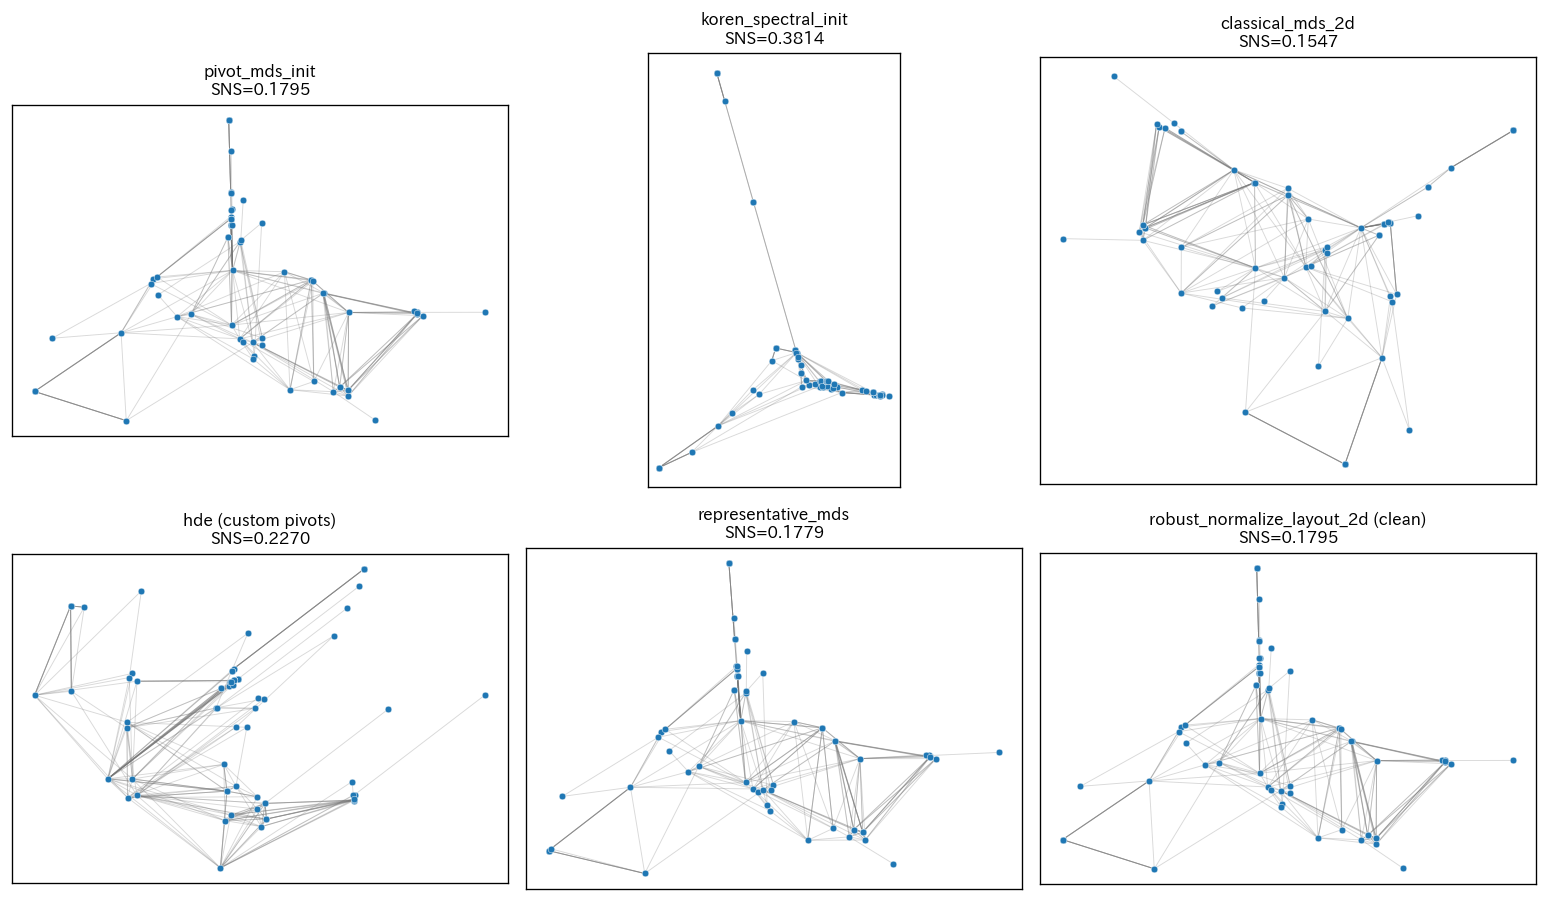

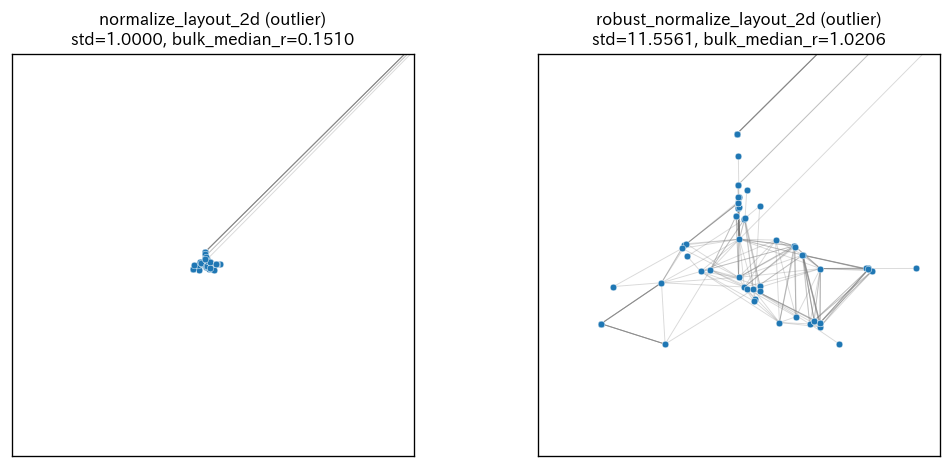

In [ ]:
\
g_lesmis = eg.load_dataset("lesmis")

# Compare 2D initializers on 'lesmis' (N=77)
pivots = eg.select_maxmin_sp_pivots(g_lesmis, num_pivots=24, seed=42)
dm_lesmis = eg.all_pairs_bfs(g_lesmis)

l_pmds = eg.pivot_mds_init(g_lesmis, num_pivots=30, seed=42)
l_pmds_gen = eg.PivotMds(g_lesmis, num_pivots=30, seed=42).generate()
assert np.allclose(l_pmds.coords(copy=False), l_pmds_gen.coords(copy=False))
l_pmds_dm = eg.pivot_mds_from_distances(dm_lesmis[:, pivots], seed=42)
l_koren = eg.koren_spectral_init(g_lesmis, seed=42)
# Note: classical_mds / classical_mds_2d is O(N^3); keep for small graphs like lesmis/karate
l_cmds = eg.classical_mds_2d(g_lesmis)
l_cmds_3d = eg.classical_mds(g_lesmis, dims=3)
l_hde = eg.hde(g_lesmis, dimensions=30, pivots=pivots, seed=42)
l_rep_nd = eg.representative_mds(dm_lesmis[:, pivots], dims=2)
l_rep = eg.Layout2d.from_coords(l_rep_nd.coords(copy=False))
print(
    f"pivot_mds_from_distances SNS={eg.scale_normalized_stress(g_lesmis, l_pmds_dm):.4f} | "
    f"classical_mds(dims=3) shape={l_cmds_3d.coords(copy=False).shape}, dims={l_cmds_3d.dims}"
)

# Compare standard vs robust normalization on an outlier-perturbed copy
coords_outlier = l_pmds.copy_coords()
coords_outlier[0] += np.array([100.0, 100.0])

l_norm_std = eg.Layout2d.from_coords(coords_outlier.copy())
eg.normalize_layout_2d(l_norm_std, target_std=1.0)
l_norm_rob = eg.Layout2d.from_coords(coords_outlier.copy())
eg.robust_normalize_layout_2d(l_norm_rob, target_std=1.0, quantile=0.95)

c_std = l_norm_std.coords(copy=False)
c_rob = l_norm_rob.coords(copy=False)
med_std = np.median(np.linalg.norm(c_std[1:], axis=1))
med_rob = np.median(np.linalg.norm(c_rob[1:], axis=1))
print(
    f"normalize_layout_2d -> std={c_std.std():.4f}, bulk_median_r={med_std:.4f} | "
    f"robust_normalize_layout_2d -> std={c_rob.std():.4f}, bulk_median_r={med_rob:.4f}"
)

# Clean robust-normalized layout for the 6-panel initializer comparison
l_norm_rob_clean = eg.Layout2d.from_coords(l_pmds.copy_coords())
eg.robust_normalize_layout_2d(l_norm_rob_clean, target_std=1.0, quantile=0.95)

init_items = [
    ("pivot_mds_init", l_pmds),
    ("koren_spectral_init", l_koren),
    ("classical_mds_2d", l_cmds),
    ("hde (custom pivots)", l_hde),
    ("representative_mds", l_rep),
    ("robust_normalize_layout_2d (clean)", l_norm_rob_clean),
]

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, lay) in zip(axes.ravel(), init_items):
    sns = eg.scale_normalized_stress(g_lesmis, lay)
    plot_graph_2d(g_lesmis, lay, ax=ax, title=f"{name}\nSNS={sns:.4f}")
plt.tight_layout()
plt.show()

# Visualize bulk collapse vs preservation under the same coordinate window
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (title, lay, med_r) in zip(
    axes,
    [
        ("normalize_layout_2d (outlier)", l_norm_std, med_std),
        ("robust_normalize_layout_2d (outlier)", l_norm_rob, med_rob),
    ],
):
    plot_graph_2d(
        g_lesmis,
        lay,
        ax=ax,
        title=f"{title}\nstd={lay.coords(copy=False).std():.4f}, bulk_median_r={med_r:.4f}",
    )
    ax.set_xlim(-3.2, 3.2)
    ax.set_ylim(-3.2, 3.2)
plt.tight_layout()
plt.show()

\
## 3. `Layout3d`・`hde_nd`・`rd_mds` と 3D ストレス最適化 (`target="layout3d"` / `"layout_nd"`)

v6 API フリーズでは、多レイアウト対応ソルバ構築時に **`target="layout3d"`**（`Layout3d` 用）または **`target="layout_nd"`**（任意次元 `LayoutNd` 用）を明示指定します。`PivotMds` / `Hde` / `RdMds` などの `LayoutGenerator` も `target="layout3d"` で直接 `Layout3d` を生成でき、`hde_nd(..., output_dims=3)` や `rd_mds(..., dims=3)` が返す `LayoutNd` と同様に `StressMajorizationSolver` や `scale_normalized_stress` で扱えます。

3D SNS on dwt_1005: hde_nd=0.0257, rd_mds=0.0671, StressMaj(layout3d)=0.0129, StressMaj(layout_nd)=0.0146


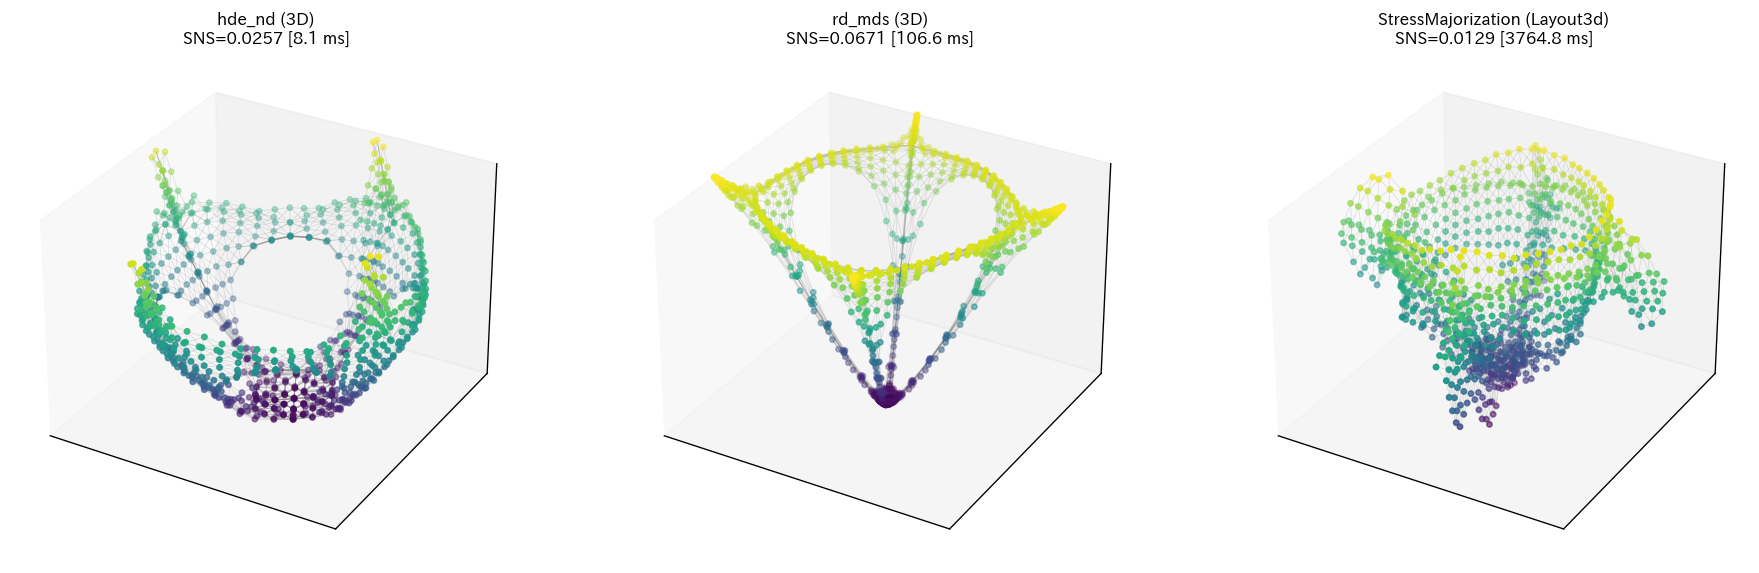

In [ ]:
\
g_dwt = eg.load_dataset("dwt_1005")

t0 = time.perf_counter()
nd_hde3 = eg.hde_nd(g_dwt, dimensions=50, output_dims=3, seed=42)
dt_hde = (time.perf_counter() - t0) * 1000

t0 = time.perf_counter()
nd_rd3 = eg.rd_mds(g_dwt, dims=3, seed=42)
dt_rd = (time.perf_counter() - t0) * 1000

# Optimize 3D Layout3d directly via target="layout3d" and LayoutNd via target="layout_nd"
l3d_sm = eg.PivotMds(g_dwt, target="layout3d", num_pivots=50, seed=42).generate()
t0 = time.perf_counter()
eg.StressMajorizationSolver.from_graph(g_dwt, target="layout3d", max_iterations=40).run(l3d_sm)
dt_sm3 = (time.perf_counter() - t0) * 1000

nd_sm3 = nd_hde3.copy()
eg.StressMajorizationSolver.from_graph(g_dwt, target="layout_nd", max_iterations=40).run(nd_sm3)

sns_hde3 = eg.scale_normalized_stress(g_dwt, nd_hde3)
sns_rd3 = eg.scale_normalized_stress(g_dwt, nd_rd3)
sns_sm3 = eg.scale_normalized_stress(g_dwt, l3d_sm)
sns_nd_sm3 = eg.scale_normalized_stress(g_dwt, nd_sm3)
print(f"3D SNS on dwt_1005: hde_nd={sns_hde3:.4f}, rd_mds={sns_rd3:.4f}, StressMaj(layout3d)={sns_sm3:.4f}, StressMaj(layout_nd)={sns_nd_sm3:.4f}")

fig = plt.figure(figsize=(15.5, 4.8))
ax1 = fig.add_subplot(1, 3, 1, projection="3d")
plot_graph_3d(g_dwt, nd_hde3, ax1, title=f"hde_nd (3D)\nSNS={sns_hde3:.4f} [{dt_hde:.1f} ms]")

ax2 = fig.add_subplot(1, 3, 2, projection="3d")
plot_graph_3d(g_dwt, nd_rd3, ax2, title=f"rd_mds (3D)\nSNS={sns_rd3:.4f} [{dt_rd:.1f} ms]")

ax3 = fig.add_subplot(1, 3, 3, projection="3d")
plot_graph_3d(g_dwt, l3d_sm, ax3, title=f"StressMajorization (Layout3d)\nSNS={sns_sm3:.4f} [{dt_sm3:.1f} ms]")

plt.tight_layout()
plt.show()

## 4. ストレス・Kamada-Kawai・MaxentStress・GRIP ソルバ

- `StressMajorizationSolver`: `.from_graph` および `.from_distance_matrix`（`np.inf` による非到達ペア指定やカスタム重み付き距離行列に対応）、`.compute_stress(layout)` / `.last_stress` を提供します。
- `KamadaKawaiSolver`: `.from_graph` / `.from_distance_matrix` による古典的なバネ・ストレス最適化。
- `MaxentStressSolver`: Barnes-Hut 近似と共役勾配法を用いた大規模向け Maxent-Stress ソルバ。
- `GripSolver`: マルチレベル力学的レイアウト。**注意**: `GripSolver.run()` は渡された初期座標を上書きして自身のマルチレベル初期化から計算します。

StressMajorization (karate): init_stress=91.52, last_stress=41.96, iters=78, status=converged
MaxentStress (qh882): effective_q=0.0, current_alpha=0.0270
GripSolver (qh882): num_levels=7, diff between zero/random init=0.00e+00


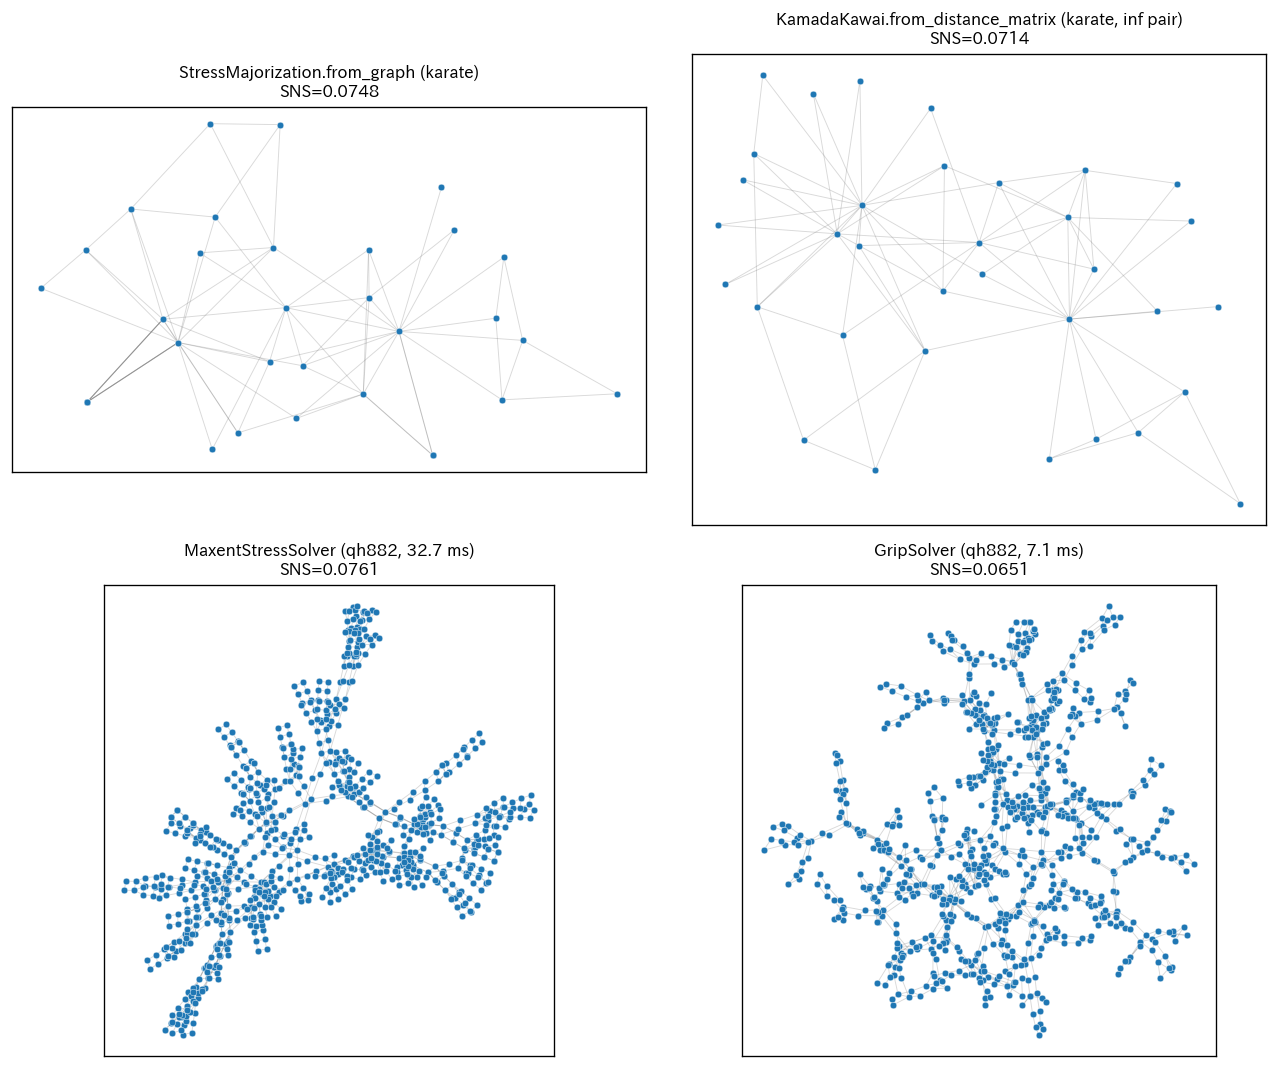

In [ ]:
g_karate = eg.load_dataset("karate")
g_qh = eg.load_dataset("qh882")

# 1) StressMajorizationSolver.from_graph & compute_stress
l_sm = eg.pivot_mds_init(g_karate, num_pivots=16, seed=42)
sm = eg.StressMajorizationSolver.from_graph(g_karate, max_iterations=80)
init_stress = sm.compute_stress(l_sm)
sm.run(l_sm)
print(
    f"StressMajorization (karate): init_stress={init_stress:.2f}, "
    f"last_stress={sm.last_stress:.2f}, iters={sm.iteration}, status={sm.status}"
)

# 2) StressMajorizationSolver.from_distance_matrix with np.inf (disconnected pair weight = 0)
dm_custom = eg.all_pairs_bfs(g_karate).copy()
dm_custom[0, 33] = np.inf
dm_custom[33, 0] = np.inf
l_sm_dm = eg.Layout2d.init(g_karate.num_nodes, seed=42)
eg.StressMajorizationSolver.from_distance_matrix(dm_custom).run(l_sm_dm)

# 3) KamadaKawaiSolver.from_graph & from_distance_matrix
l_kk = eg.pivot_mds_init(g_karate, num_pivots=16, seed=42)
kk = eg.KamadaKawaiSolver.from_graph(g_karate)
kk.run(l_kk)

l_kk_dm = eg.Layout2d.init(g_karate.num_nodes, seed=42)
eg.KamadaKawaiSolver.from_distance_matrix(dm_custom).run(l_kk_dm)

# 4) MaxentStressSolver and GripSolver on qh882 (N=882)
l_maxent = eg.pivot_mds_init(g_qh, num_pivots=50, seed=42)
t0 = time.perf_counter()
maxent = eg.MaxentStressSolver(g_qh, stages=4, steps_per_stage=30, seed=42)
maxent.run(l_maxent)
dt_maxent = (time.perf_counter() - t0) * 1000
print(f"MaxentStress (qh882): effective_q={maxent.effective_q}, current_alpha={maxent.current_alpha:.4f}")

# Note: GripSolver overwrites initial coordinates internally
l_grip_from_zeros = eg.Layout2d.zeros(g_qh.num_nodes)
l_grip_from_rand = eg.Layout2d.init(g_qh.num_nodes, seed=99)
t0 = time.perf_counter()
grip = eg.GripSolver(g_qh, seed=42)
grip.run(l_grip_from_zeros)
dt_grip = (time.perf_counter() - t0) * 1000
eg.GripSolver(g_qh, seed=42).run(l_grip_from_rand)
max_diff = np.abs(l_grip_from_zeros.coords(copy=False) - l_grip_from_rand.coords(copy=False)).max()
print(f"GripSolver (qh882): num_levels={grip.num_levels}, diff between zero/random init={max_diff:.2e}")

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
panels = [
    ("StressMajorization.from_graph (karate)", g_karate, l_sm),
    ("KamadaKawai.from_distance_matrix (karate, inf pair)", g_karate, l_kk_dm),
    (f"MaxentStressSolver (qh882, {dt_maxent:.1f} ms)", g_qh, l_maxent),
    (f"GripSolver (qh882, {dt_grip:.1f} ms)", g_qh, l_grip_from_zeros),
]
for ax, (title, g_cur, l_cur) in zip(axes.ravel(), panels):
    sns = eg.scale_normalized_stress(g_cur, l_cur)
    plot_graph_2d(g_cur, l_cur, ax=ax, title=f"{title}\nSNS={sns:.4f}")
plt.tight_layout()
plt.show()

## 5. `SgdSolver` の協調実行 (`step` / `run_steps`) とスケジュール比較

すべてのソルバはシングルスレッド環境でも柔軟に進捗を監視できるよう、`step()`（1 ステップ実行）および `run_steps(layout, k)`（k ステップ実行）を提供しています。
ここでは `SgdSolver.full` を使い、6 種類の学習率スケジュール（`"exponential"`, `"linear"`, `"quadratic"`, `"reciprocal"`, `"constant"`, `"squared"`）ごとの収束曲線 (`SNS` と `current_eta`) を比較します。

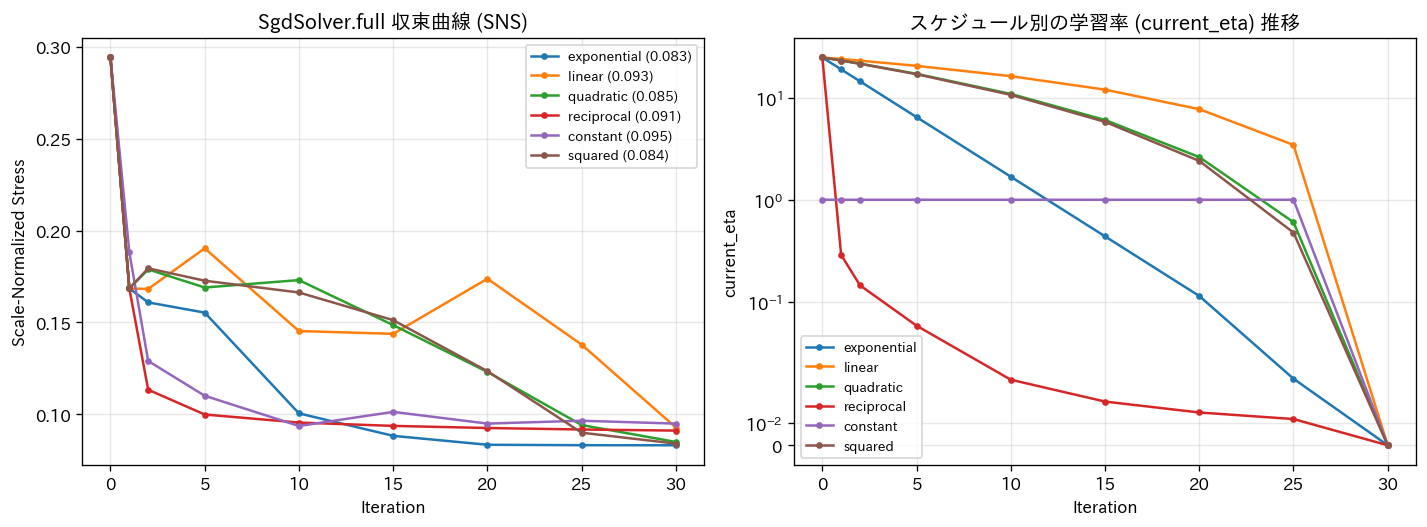

In [ ]:
\
schedules = ["exponential", "linear", "quadratic", "reciprocal", "constant", "squared"]
iters = 30
checkpoints = [0, 2, 5, 10, 15, 20, 25, 30]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for sched in schedules:
    lay = eg.Layout2d.init(g_lesmis.num_nodes, seed=42)
    solver = eg.SgdSolver.full(g_lesmis, iterations=iters, schedule=sched, seed=42)
    sns_hist = [eg.scale_normalized_stress(g_lesmis, lay)]
    eta_hist = [solver.current_eta]

    # Cooperative stepping loop using step() and run_steps()
    solver.step(lay)
    sns_hist.append(eg.scale_normalized_stress(g_lesmis, lay))
    eta_hist.append(solver.current_eta)
    step_pts = [0, 1]

    for target in checkpoints[1:]:
        if target > solver.iteration:
            solver.run_steps(lay, target - solver.iteration)
            step_pts.append(solver.iteration)
            sns_hist.append(eg.scale_normalized_stress(g_lesmis, lay))
            eta_hist.append(solver.current_eta)

    axes[0].plot(step_pts, sns_hist, marker="o", markersize=3, label=f"{sched} ({sns_hist[-1]:.3f})")
    axes[1].plot(step_pts, eta_hist, marker="o", markersize=3, label=sched)

axes[0].set_title("SgdSolver.full 収束曲線 (SNS)")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Scale-Normalized Stress")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].set_title("スケジュール別の学習率 (current_eta) 推移")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("current_eta")
axes[1].set_yscale("symlog", linthresh=0.05)
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

\
## 6. スケーラブル SGD ソルバ群とカスタムペア制約

中〜大規模グラフ向けに、`SgdSolver` は計算量を抑えた各種バリアントを提供します（反復回数引数はすべて `iterations` に統一されています）。

- `Sgd2Solver`: 独立クラス化されたバッチ化 SGD2 ソルバ
- `SgdSolver.ortmann_sparse_stress`: ピボットベースのスパースストレス
- `SgdSolver.random_pair`: ランダムペアサンプリング
- `SgdSolver.omega`: 高次元埋め込み（`compute_resistance_embedding` 推奨）の距離に基づくペア選定
- `SgdSolver.streaming_negatives`: ストリーミング負例ヒンジ制約
- `SgdSolver.from_pairs` / `SgdSolver.from_pairs_with_hinges` / `SgdSolver.from_packed_symmetric`: 任意のバネ・ヒンジ制約を直接指定（`from_pairs` と `from_pairs_with_hinges` のオプション配列 `spring_dji, spring_wij, spring_wji` 等はキーワード専用引数・既定値 `None` です）

from_pairs_with_hinges: num_springs=6, num_hinges=3 | from_packed_symmetric max_diff=0.00e+00


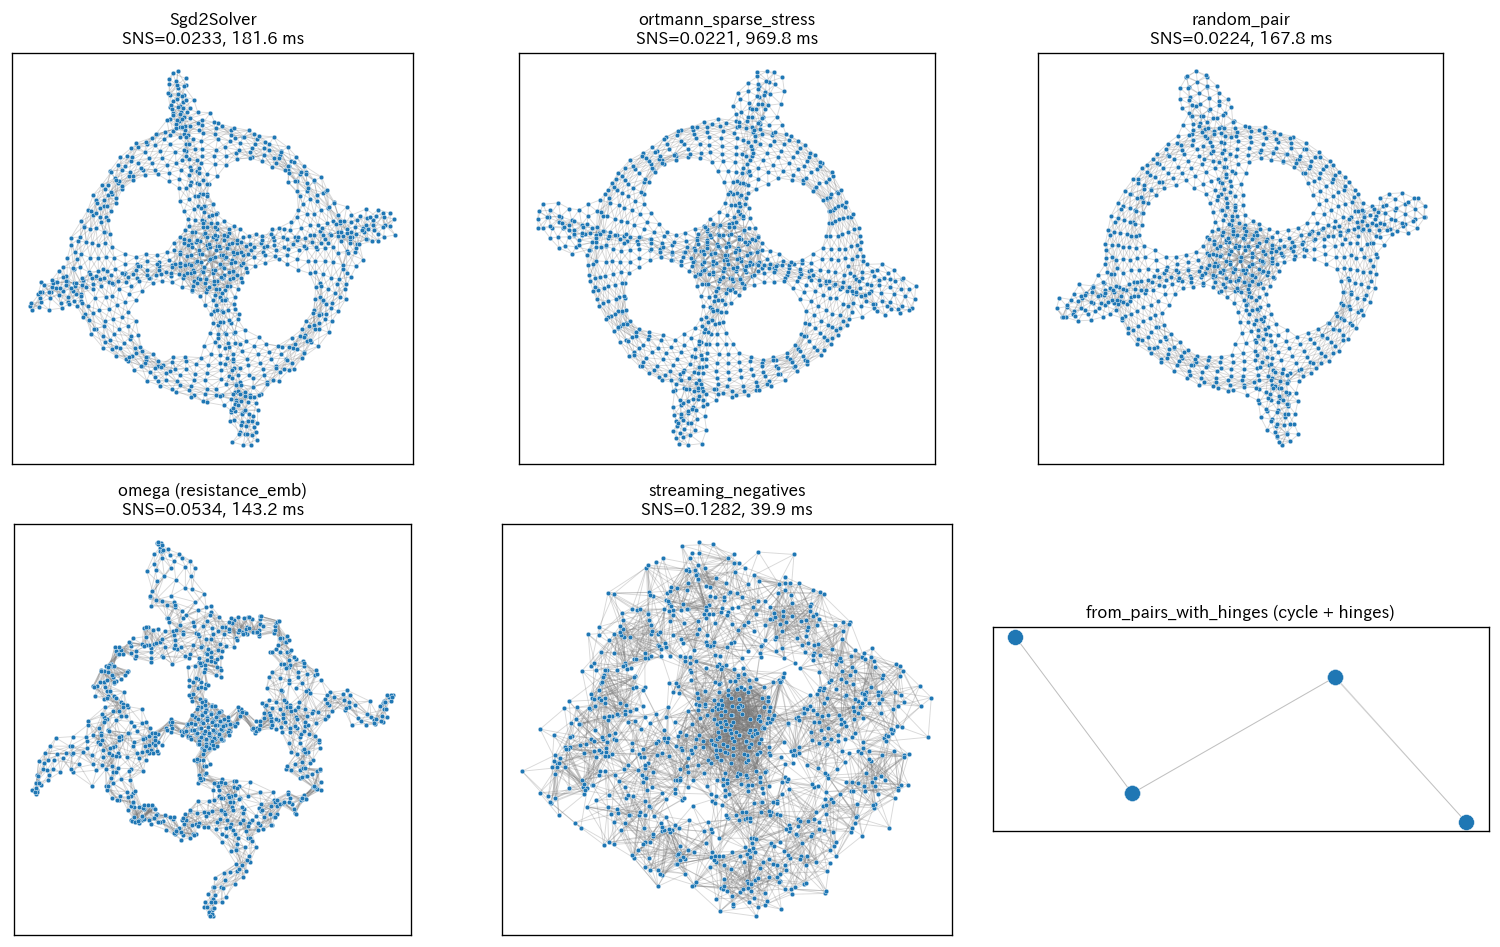

In [ ]:
\
res_emb, _ = eg.compute_resistance_embedding(g_dwt, dim=16, seed=42)

sgd_configs = [
    ("Sgd2Solver", lambda: eg.Sgd2Solver(g_dwt, iterations=60, seed=42)),
    (
        "ortmann_sparse_stress",
        lambda: eg.SgdSolver.ortmann_sparse_stress(g_dwt, num_pivots=80, pivot_strategy="kmeans_sp", iterations=120, seed=42),
    ),
    ("random_pair", lambda: eg.SgdSolver.random_pair(g_dwt, pairs_per_node=30, iterations=60, seed=42)),
    ("omega (resistance_emb)", lambda: eg.SgdSolver.omega(g_dwt, res_emb, k=30, iterations=60, seed=42)),
    ("streaming_negatives", lambda: eg.SgdSolver.streaming_negatives(g_dwt, negatives_per_node=5, iterations=60, seed=42)),
]

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, make_solver) in zip(axes.ravel()[:5], sgd_configs):
    lay = eg.pivot_mds_init(g_dwt, num_pivots=50, seed=42)
    t0 = time.perf_counter()
    solver = make_solver()
    solver.run(lay)
    dt = (time.perf_counter() - t0) * 1000
    sns = eg.scale_normalized_stress(g_dwt, lay)
    plot_graph_2d(g_dwt, lay, ax=ax, title=f"{name}\nSNS={sns:.4f}, {dt:.1f} ms", node_size=8)

# 6th panel: Custom constraints via from_pairs, from_pairs_with_hinges, and from_packed_symmetric
g_cycle = eg.CsrGraph.from_edges(6, [[0, 1], [1, 2], [2, 3], [3, 4], [4, 5], [5, 0]])
src = np.array([0, 1, 2, 3, 4, 5], dtype=np.uint32)
tgt = np.array([1, 2, 3, 4, 5, 0], dtype=np.uint32)
dij = np.ones(6, dtype=np.float64)
h_src = np.array([0, 1, 2], dtype=np.uint32)
h_tgt = np.array([3, 4, 5], dtype=np.uint32)
h_dij = np.full(3, 2.5, dtype=np.float64)

lay_fp = eg.Layout2d.init(6, seed=42)
eg.SgdSolver.from_pairs(6, src, tgt, dij, iterations=60, seed=42).run(lay_fp)

lay_hinge = eg.Layout2d.init(6, seed=42)
solver_hinge = eg.SgdSolver.from_pairs_with_hinges(
    6, src, tgt, dij, h_src, h_tgt, h_dij, iterations=60, seed=42
)
solver_hinge.run(lay_hinge)

# Packed symmetric representation combining springs and hinges
p_src = np.concatenate([src, h_src])
p_tgt = np.concatenate([tgt, h_tgt])
p_dists = np.concatenate([dij, h_dij])
p_weights = np.concatenate([1.0 / (dij ** 2), 1.0 / (h_dij ** 2)])
is_hinge = [False] * len(src) + [True] * len(h_src)
lay_packed = eg.Layout2d.init(6, seed=42)
solver_packed = eg.SgdSolver.from_packed_symmetric(6, p_src, p_tgt, p_dists, p_weights, is_hinge, iterations=60, seed=42)
solver_packed.run(lay_packed)

print(
    f"from_pairs_with_hinges: num_springs={solver_hinge.num_springs}, num_hinges={solver_hinge.num_hinges} | "
    f"from_packed_symmetric max_diff={np.abs(lay_hinge.coords(copy=False) - lay_packed.coords(copy=False)).max():.2e}"
)
plot_graph_2d(g_cycle, lay_hinge, ax=axes.ravel()[5], title="from_pairs_with_hinges (cycle + hinges)", node_size=90)

plt.tight_layout()
plt.show()